<a href="https://colab.research.google.com/github/Huriel-M/aplicativo-salud-cultivo-papa/blob/main/Codigo_F_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# CARGA AUTOMÁTICA DE BANDAS SENTINEL-2

import os
import csv
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

BAND_FOLDER = "/content/drive/MyDrive/Proyecto_Grado_Documentos./Imagenes_10"

OUTDIR = "/content/spectral_results"
os.makedirs(OUTDIR, exist_ok=True)

BAND_WAVELENGTHS = {    "B01": 443,    "B02": 490,    "B03": 560,    "B04": 665,    "B05": 705,    "B06": 740,
                        "B07": 783,    "B08": 842,    "B8A": 865,    "B09": 945,    "B11": 1610,   "B12": 2190  }

print(" CARGA DE BANDAS SENTINEL-2")
print("Formato: TIFF float")
print("Escala: reflectancia")

bands = {}
band_metadata = {}


# Detectar y cargar bandas
for banda in BAND_WAVELENGTHS:

    archivos = [f for f in os.listdir(BAND_FOLDER) if f.lower().endswith((".tif", ".tiff")) and f"_{banda}_" in f.upper()]

    if len(archivos) == 0:
        print(f"✗ {banda}: faltante")
        continue

    if len(archivos) > 1:
        print(f" {banda}: múltiples archivos encontrados")
        continue

    ruta = os.path.join(BAND_FOLDER, archivos[0])

    try:
        with rasterio.open(ruta) as src:

            dtype = src.dtypes[0]

            if dtype not in ["uint16", "int16", "float32", "float64"]:
                print(f"✗ {banda}: tipo {dtype} no compatible")
                continue

            datos = src.read(1).astype(np.float32)

            bands[banda] = datos

            band_metadata[banda] = {"dtype": dtype, "shape": src.shape, "resolution": src.res, "crs": src.crs}

            print(f"✓ {banda} | " f"{dtype} | " f"shape={src.shape} | " f"min={np.nanmin(datos):.4f} | " f"max={np.nanmax(datos):.4f}")

    except Exception as e:
        print(f"✗ {banda}: error → {e}")


# Resumen de bandas

disponibles = list(bands.keys())
faltantes = [ banda for banda in BAND_WAVELENGTHS if banda not in bands]

print(" RESUMEN")
print("=" * 60)

print("Disponibles:", disponibles)
print("Faltantes:", faltantes)

if len(bands) == 12:
    print("✓ Carga completa: 12/12 bandas.")

elif len(bands) > 0:
    print(f"✓ Carga parcial: {len(bands)}/12 bandas.")
    print("  Los índices se calcularán solo si tienen")
    print("  todas las bandas requeridas.")

else:
    print("✗ No hay bandas válidas para procesar.")

 CARGA DE BANDAS SENTINEL-2
Formato: TIFF float
Escala: reflectancia
✓ B01 | float32 | shape=(1259, 2413) | min=0.0030 | max=0.1593
✓ B02 | float32 | shape=(1259, 2413) | min=0.0000 | max=1.5272
✓ B03 | float32 | shape=(1259, 2413) | min=0.0000 | max=1.4978
✓ B04 | float32 | shape=(1259, 2413) | min=0.0000 | max=1.6417
✓ B05 | float32 | shape=(1259, 2413) | min=0.0139 | max=0.6903
✓ B06 | float32 | shape=(1259, 2413) | min=0.0258 | max=0.6527
✓ B07 | float32 | shape=(1259, 2413) | min=0.0277 | max=0.8162
✓ B08 | float32 | shape=(1259, 2413) | min=0.0291 | max=1.5569
✓ B8A | float32 | shape=(1259, 2413) | min=0.0368 | max=0.9708
✓ B09 | float32 | shape=(1259, 2413) | min=0.0922 | max=0.6953
✓ B11 | float32 | shape=(1259, 2413) | min=0.0312 | max=0.5997
✓ B12 | float32 | shape=(1259, 2413) | min=0.0151 | max=0.5418
 RESUMEN
Disponibles: ['B01', 'B02', 'B03', 'B04', 'B05', 'B06', 'B07', 'B08', 'B8A', 'B09', 'B11', 'B12']
Faltantes: []
✓ Carga completa: 12/12 bandas.


In [3]:
# CONTROL DE COMPATIBILIDAD ESPACIAL

shapes = {m["shape"] for m in band_metadata.values()}
resolutions = {m["resolution"] for m in band_metadata.values()}
crs_values = {str(m["crs"]) for m in band_metadata.values()}

if len(shapes) == 1 and len(resolutions) == 1 and len(crs_values) == 1:

    print("✓ Todas las bandas tienen dimensiones, resolución y CRS compatibles.")

else:
    print(" ERROR: Las bandas no son espacialmente compatibles.")
    print("Revise las bandas descargadas y vuelva a cargarlas.")

    raise ValueError("Procesamiento detenido: las bandas tienen "
                     "diferencias de dimensiones, resolución o CRS.")

✓ Todas las bandas tienen dimensiones, resolución y CRS compatibles.


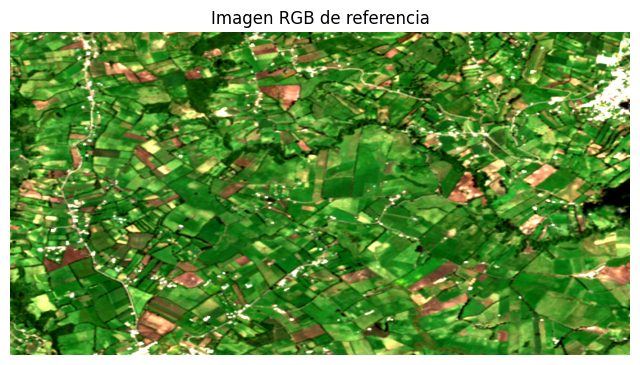

In [4]:
# VISUALIZACIÓN RGB DE REFERENCIA

rgb = np.dstack((    bands["B04"],  # Rojo
                     bands["B03"],  # Verde
                     bands["B02"]   # Azul
))

# Ajuste de contraste
p2, p98 = np.nanpercentile(rgb, (2, 98))

rgb_vis = np.clip((rgb - p2) / (p98 - p2), 0, 1)

plt.figure(figsize=(8, 8))
plt.imshow(rgb_vis)
plt.title("Imagen RGB de referencia")
plt.axis("off")
plt.show()

In [5]:
NIR = bands["B08"]
RED = bands["B04"]
GREEN = bands["B03"]
BLUE = bands["B02"]
REDEDGE = bands["B05"]
SWIR = bands["B11"]

epsilon = 1e-6

In [6]:
# FUNCIONES GENERALES Y REGISTRO DE RESULTADOS

# Diccionarios para registrar resultados
indices_calculados = {}
indices_no_calculados = {}

# LIMPIEZA DE ÍNDICES

def limpiar_indice(indice, mascara=None, limite=None):
    """ Elimina valores no válidos y aplica la máscara de vegetación
    cuando corresponde.

    Si se proporciona 'limite', el índice se limita a ese rango.
    Esto permite conservar la escala nativa de índices como RCI,
    TCARI/OSAVI y LAI cuando no corresponde aplicar [-1, 1]."""

    indice = np.where(np.isfinite(indice), indice, np.nan)

    if limite is not None:
        indice = np.clip(indice, limite[0], limite[1])

    if mascara is not None:
        indice[~mascara] = np.nan

    return indice

# VISUALIZACIÓN Y ESTADÍSTICAS

def visualizar_indice(indice, titulo, cmap):
    """ Visualiza el índice utilizando los percentiles 2 y 98
    para mejorar la representación espacial y muestra
    estadísticas básicas. """

    valores = indice[np.isfinite(indice)]

    if valores.size == 0:
        print(f" {titulo}: no hay valores válidos.")
        return

    vmin = np.percentile(valores, 2)
    vmax = np.percentile(valores, 98)

    plt.figure(figsize=(6, 6))

    plt.imshow(indice, cmap=cmap, vmin=vmin, vmax=vmax)

    plt.title(titulo)
    plt.colorbar(label="Valor")
    plt.axis("off")
    plt.show()

    print(f"{titulo} promedio = {np.nanmean(indice):.4f}")
    print(f"{titulo} std = {np.nanstd(indice):.4f}")

 NDVI

Definición:
El NDVI permite evaluar la presencia y el vigor general de la vegetación a partir de la respuesta espectral enlas bandas del rojo (B04) y del infrarrojo cercano (B08).

✓ NDVI calculado correctamente.

Estadísticas:
  Promedio = 0.7751
  Desviación estándar = 0.1282


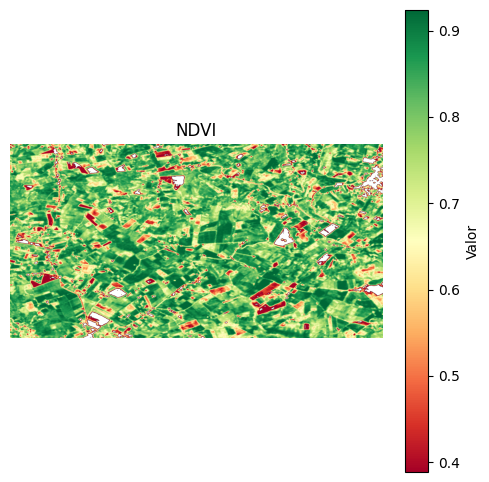

NDVI promedio = 0.7751
NDVI std = 0.1282

Interpretación:
Vegetación verde de moderada a densa.


In [7]:
# 1. NDVI - ÍNDICE DE VEGETACIÓN DE DIFERENCIA NORMALIZADA

print(" NDVI")

# DEFINICIÓN
definicion_ndvi = ("El NDVI permite evaluar la presencia y el vigor general de la vegetación a partir de la respuesta espectral en"
                   "las bandas del rojo (B04) y del infrarrojo cercano (B08).")

print("\nDefinición:")
print(definicion_ndvi)

# BANDAS REQUERIDAS

bandas_requeridas = ["B04", "B08"]

faltantes = [banda for banda in bandas_requeridas if banda not in bands]

# CÁLCULO

if not faltantes:

    NDVI = ((NIR - RED) / (NIR + RED + epsilon))

    # LIMPIEZA DEL ÍNDICE
    NDVI = limpiar_indice(NDVI, limite=(-1, 1))

    # MÁSCARA DE VEGETACIÓN
    veg_mask = NDVI > 0.3
    NDVI[~veg_mask] = np.nan

    # REGISTRO DEL RESULTADO

    indices_calculados["NDVI"] = {"bandas": bandas_requeridas, "escala": "[-1, 1]"}

    print("\n✓ NDVI calculado correctamente.")


    # ESTADÍSTICAS
    valores_validos = NDVI[np.isfinite(NDVI)]

    if valores_validos.size > 0:

        promedio_ndvi = np.nanmean(NDVI)
        desviacion_ndvi = np.nanstd(NDVI)

        print("\nEstadísticas:")
        print(f"  Promedio = {promedio_ndvi:.4f}")
        print(f"  Desviación estándar = {desviacion_ndvi:.4f}")

    else:
        promedio_ndvi = np.nan

        print("\n NDVI calculado, pero no hay "
              "valores válidos dentro de la máscara.")

    # MAPA DEL NDVI
    visualizar_indice(NDVI, "NDVI", cmap="RdYlGn")

    # INTERPRETACIÓN
    def interpretar_ndvi(valor):

        if np.isnan(valor):
            return "Sin datos válidos para interpretar."

        elif valor < 0:
            return ("Superficies que no corresponden a vegetación verde; pueden incluir agua, sombra o infraestructura.")

        elif valor < 0.2:
            return ("Suelo expuesto o cobertura vegetal muy escasa.")

        elif valor < 0.5:
            return ("Vegetación dispersa o un dosel aún abierto.")

        elif valor < 0.8:
            return ("Vegetación verde de moderada a densa.")

        elif valor <= 1:
            return ("Dosel verde muy denso; el NDVI puede perder sensibilidad.")

        else:
            return "Valor fuera del rango de referencia."

    print("\nInterpretación:")
    print(interpretar_ndvi(promedio_ndvi))

# BANDAS FALTANTES
else:
    indices_no_calculados["NDVI"] = {"faltantes": faltantes}

    print("\n NDVI no calculado. "
          f"Faltan las bandas: {', '.join(faltantes)}")

Calculo Indices

 NDRE

Definición:
El NDRE permite evaluar el estado y la densidad de la vegetación utilizando una banda del borde rojo (Red Edge) y el infrarrojo cercano(NIR). Es especialmente útil para analizar cambios asociados con el contenido de clorofila y el desarrollo de la vegetación.

✓ NDRE calculado correctamente.

Estadísticas:
  Promedio = 0.5102
  Desviación estándar = 0.0997


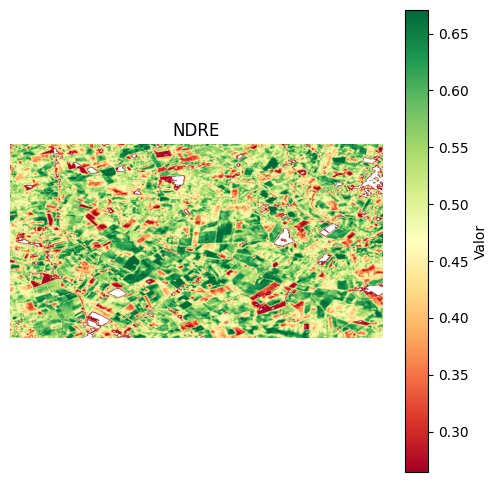

NDRE promedio = 0.5102
NDRE std = 0.0997

Interpretación:
Densidad media de vegetación.


In [8]:
# 2. NDRE - ÍNDICE DE DIFERENCIA NORMALIZADA RED EDGE

print(" NDRE")

# DEFINICIÓN

definicion_ndre = ("El NDRE permite evaluar el estado y la densidad de la vegetación utilizando una banda del borde rojo (Red Edge) y el infrarrojo cercano"
                   "(NIR). Es especialmente útil para analizar cambios asociados con el contenido de clorofila y el desarrollo de la vegetación.")

print("\nDefinición:")
print(definicion_ndre)

# BANDAS Y CONDICIONES REQUERIDAS
bandas_requeridas = ["B05", "B08"]

faltantes = [ banda for banda in bandas_requeridas if banda not in bands]

if not faltantes and "veg_mask" in globals():

    # CÁLCULO

    NDRE = ((NIR - REDEDGE) / (NIR + REDEDGE + epsilon))

    # LIMPIEZA DEL ÍNDICE

    NDRE = limpiar_indice(NDRE, mascara=veg_mask, limite=(-1, 1))

    # REGISTRO DEL RESULTADO

    indices_calculados["NDRE"] = {"bandas": bandas_requeridas, "escala": "[-1, 1]", "depende_de": "veg_mask"}
    print("\n✓ NDRE calculado correctamente.")

    # ESTADÍSTICAS
    valores_validos = NDRE[np.isfinite(NDRE)]

    if valores_validos.size > 0:

        promedio_ndre = np.nanmean(NDRE)
        desviacion_ndre = np.nanstd(NDRE)

        print("\nEstadísticas:")
        print(f"  Promedio = {promedio_ndre:.4f}")
        print(f"  Desviación estándar = {desviacion_ndre:.4f}")

    else:
        promedio_ndre = np.nan

        print("\n NDRE calculado, pero no hay "
              "valores válidos dentro de la máscara.")


    # MAPA DEL NDRE
    visualizar_indice(NDRE, "NDRE", cmap="RdYlGn")


    # INTERPRETACIÓN

    def interpretar_ndre(valor):

        if np.isnan(valor):
            return "Sin datos válidos para interpretar."

        elif valor < 0:
            return ("Suelo o ausencia de vegetación.")

        elif valor < 0.3:
            return ("Vegetación escasa; puede corresponder a etapas tempranas de desarrollo del cultivo.")

        elif valor < 0.6:
            return ("Densidad media de vegetación.")

        elif valor <= 1:
            return ("Alta densidad de vegetación; puede corresponder a etapas avanzadas de desarrollo.")

        else:
            return "Valor fuera del rango de referencia."

    print("\nInterpretación:")
    print(interpretar_ndre(promedio_ndre))


# CASOS EN LOS QUE NO SE PUEDE CALCULAR

elif faltantes:

    indices_no_calculados["NDRE"] = {"faltantes": faltantes}

    print("\n NDRE no calculado. "
          f"Faltan las bandas: {', '.join(faltantes)}")

elif "veg_mask" not in globals():

    indices_no_calculados["NDRE"] = {"faltantes": ["veg_mask"]}

    print("\n NDRE no calculado. "
          "No existe la máscara de vegetación generada por NDVI.")

 EVI

Definición:
El EVI permite evaluar el vigor y la densidad de la vegetación reduciendo parcialmente la influenciadel suelo y de las condiciones atmosféricas. Utiliza las bandas del azul, rojo e infrarrojo cercano.

✓ EVI calculado correctamente.

Estadísticas:
  Promedio = 0.5994
  Desviación estándar = 0.1675


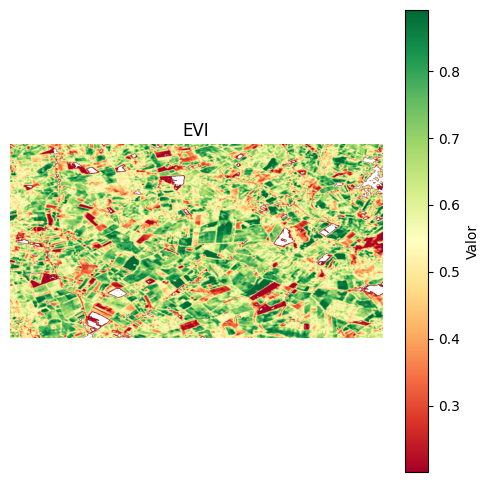

EVI promedio = 0.5994
EVI std = 0.1675

Interpretación:
Vegetación sana y moderadamente densa; cultivo bien desarrollado.


In [9]:
# 3. EVI - ÍNDICE DE VEGETACIÓN MEJORADO

print(" EVI")

# DEFINICIÓN

definicion_evi = ("El EVI permite evaluar el vigor y la densidad de la vegetación reduciendo parcialmente la influencia"
                  "del suelo y de las condiciones atmosféricas. Utiliza las bandas del azul, rojo e infrarrojo cercano.")

print("\nDefinición:")
print(definicion_evi)

# BANDAS Y CONDICIONES REQUERIDAS
bandas_requeridas = ["B02", "B04", "B08"]

faltantes = [banda for banda in bandas_requeridas if banda not in bands]

if not faltantes and "veg_mask" in globals():

    # CÁLCULO
    EVI = 2.5 * ((NIR - RED) / (NIR + 6 * RED - 7.5 * BLUE + 1 + epsilon))

    # LIMPIEZA DEL ÍNDICE
    EVI = limpiar_indice(EVI, mascara=veg_mask, limite=(-1, 1))

    # REGISTRO DEL RESULTADO
    indices_calculados["EVI"] = {"bandas": bandas_requeridas, "escala": "[-1, 1]", "depende_de": "veg_mask"}

    print("\n✓ EVI calculado correctamente.")

    # ESTADÍSTICAS
    valores_validos = EVI[np.isfinite(EVI)]

    if valores_validos.size > 0:

        promedio_evi = np.nanmean(EVI)
        desviacion_evi = np.nanstd(EVI)

        print("\nEstadísticas:")
        print(f"  Promedio = {promedio_evi:.4f}")
        print(f"  Desviación estándar = {desviacion_evi:.4f}")

    else:
        promedio_evi = np.nan

        print("\n EVI calculado, pero no hay valores válidos dentro de la máscara.")

    # MAPA DEL EVI
    visualizar_indice(EVI, "EVI", cmap="RdYlGn")

    # INTERPRETACIÓN
    def interpretar_evi(valor):

        if np.isnan(valor):
            return "Sin datos válidos para interpretar."

        elif valor < 0:
            return ("Agua, nieve, nubes u otras superficies sin vegetación.")

        elif valor < 0.2:
            return ("Vegetación escasa, suelo expuesto, crecimiento muy temprano o vegetación senescente.")

        elif valor < 0.4:
            return ("Vegetación moderada o en desarrollo; crecimiento temprano a medio.")

        elif valor < 0.6:
            return ("Vegetación sana y moderadamente densa; cultivo bien desarrollado.")

        elif valor < 0.9:
            return ("Vegetación muy densa y vigorosa; cobertura vegetal elevada.")

        elif valor <= 1:
            return ("Vegetación extremadamente densa; valores próximos a la saturación del índice.")

        else:
            return "Valor fuera del rango de referencia."

    print("\nInterpretación:")
    print(interpretar_evi(promedio_evi))

# CASOS EN LOS QUE NO SE PUEDE CALCULAR

elif faltantes:
    indices_no_calculados["EVI"] = {"faltantes": faltantes}

    print("\n EVI no calculado. "
         f"Faltan las bandas: {', '.join(faltantes)}" )

elif "veg_mask" not in globals():

    indices_no_calculados["EVI"] = {"faltantes": ["veg_mask"]}

    print("\n EVI no calculado. No existe la máscara de vegetación generada por NDVI.")

 NDMI

Definición:
El NDMI permite evaluar el contenido relativo de humedad de la vegetación utilizando la respuesta espectral del infrarrojocercano (NIR) y del infrarrojo de onda corta (SWIR). Es útil para analizar las condiciones hídricas de la cobertura vegetal.

✓ NDMI calculado correctamente.

Estadísticas:
  Promedio = 0.2684
  Desviación estándar = 0.1695


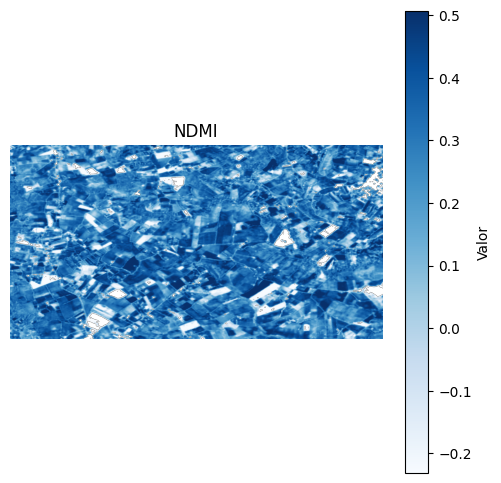

NDMI promedio = 0.2684
NDMI std = 0.1695

Interpretación:
Humedad media; condiciones generalmente adecuadas para la vegetación, sin estrés hídrico significativo.


In [10]:
# 4. NDMI - ÍNDICE DE DIFERENCIA NORMALIZADA DE HUMEDAD

print(" NDMI")

# DEFINICIÓN

definicion_ndmi = ("El NDMI permite evaluar el contenido relativo de humedad de la vegetación utilizando la respuesta espectral del infrarrojo"
                   "cercano (NIR) y del infrarrojo de onda corta (SWIR). Es útil para analizar las condiciones hídricas de la cobertura vegetal.")

print("\nDefinición:")
print(definicion_ndmi)

# BANDAS Y CONDICIONES REQUERIDAS
bandas_requeridas = ["B08", "B11"]

faltantes = [banda for banda in bandas_requeridas if banda not in bands]

if not faltantes and "veg_mask" in globals():

    # CÁLCULO
    NDMI = ((NIR - SWIR) / (NIR + SWIR + epsilon))

    # LIMPIEZA DEL ÍNDICE
    NDMI = limpiar_indice(NDMI, mascara=veg_mask, limite=(-1, 1))

    # REGISTRO DEL RESULTADO
    indices_calculados["NDMI"] = {"bandas": bandas_requeridas, "escala": "[-1, 1]", "depende_de": "veg_mask"}

    print("\n✓ NDMI calculado correctamente.")

    # ESTADÍSTICAS
    valores_validos = NDMI[np.isfinite(NDMI)]

    if valores_validos.size > 0:

        promedio_ndmi = np.nanmean(NDMI)
        desviacion_ndmi = np.nanstd(NDMI)

        print("\nEstadísticas:")
        print(f"  Promedio = {promedio_ndmi:.4f}")
        print(f"  Desviación estándar = {desviacion_ndmi:.4f}")

    else:

        promedio_ndmi = np.nan
        print("\n NDMI calculado, pero no hay valores válidos dentro de la máscara.")

    # MAPA DEL NDMI
    visualizar_indice(NDMI, "NDMI", cmap="Blues")

    # INTERPRETACIÓN
    def interpretar_ndmi(valor):

        if np.isnan(valor):
            return "Sin datos válidos para interpretar."

        elif valor < -0.4:
            return ("Ausencia o cobertura vegetal muy baja; predominan superficies secas o suelo expuesto.")

        elif valor < -0.1:
            return ("Cobertura vegetal baja y condiciones de humedad reducidas.")

        elif valor < 0.1:
            return ("Humedad baja; puede indicar presencia de estrés hídrico.")

        elif valor < 0.3:
            return ("Humedad media; condiciones generalmente adecuadas para la vegetación, sin estrés hídrico significativo.")

        elif valor < 0.5:
            return ("Alta humedad; vegetación con buena disponibilidad de agua, aunque valores elevados pueden indicar exceso de humedad.")

        elif valor <= 1:
            return ("Humedad muy alta; puede corresponder a vegetación muy húmeda o a superficies con agua libre")
        else:
            return "Valor fuera del rango de referencia."

    print("\nInterpretación:")
    print(interpretar_ndmi(promedio_ndmi))

# CASOS EN LOS QUE NO SE PUEDE CALCULAR

elif faltantes:

    indices_no_calculados["NDMI"] = {"faltantes": faltantes}

    print("\n NDMI no calculado. "
         f"Faltan las bandas: {', '.join(faltantes)}")

elif "veg_mask" not in globals():

    indices_no_calculados["NDMI"] = {"faltantes": ["veg_mask"]}

    print("\n NDMI no calculado. No existe la máscara de vegetación generada por NDVI."    )

 RCI - CLOROFILA RED EDGE

Definición:
El RCI permite evaluar cambios relativos asociados con el contenido de clorofila y el vigor de la vegetaciónmediante la relación entre la reflectancia del infrarrojo cercano (NIR) y la banda del borde rojo (Red Edge).

✓ RCI calculado correctamente.
  Escala nativa conservada.
  Rango de referencia utilizado: 0-15

Estadísticas:
  Promedio = 2.2487
  Desviación estándar = 0.8409
  Mínimo = -0.4561
  Máximo = 23.9235


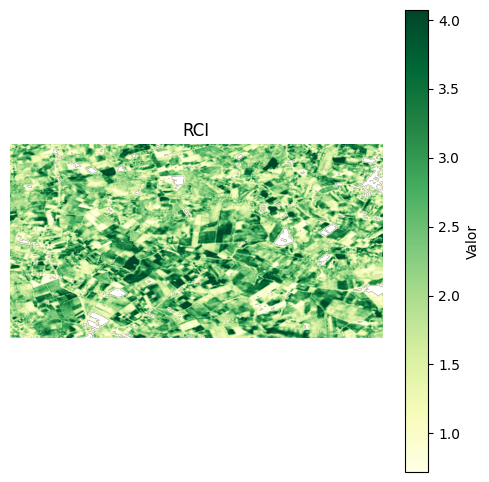

RCI promedio = 2.2487
RCI std = 0.8409

Interpretación:
Estrés alto o etapa de emergencia; puede corresponder a cultivos nacientes o plantas afectadas por deficiencias nutricionales, plagas o sequía.


In [11]:
# 5. RCI - ÍNDICE DE CLOROFILA RED EDGE

print(" RCI - CLOROFILA RED EDGE")

# DEFINICIÓN
definicion_rci = ("El RCI permite evaluar cambios relativos asociados con el contenido de clorofila y el vigor de la vegetación"
                  "mediante la relación entre la reflectancia del infrarrojo cercano (NIR) y la banda del borde rojo (Red Edge).")

print("\nDefinición:")
print(definicion_rci)

# BANDAS Y CONDICIONES REQUERIDAS
bandas_requeridas = ["B05", "B08"]

faltantes = [ banda for banda in bandas_requeridas if banda not in bands]

if not faltantes and "veg_mask" in globals():

    # CÁLCULO
    RCI = (NIR /(REDEDGE + epsilon)) - 1

    # LIMPIEZA DEL ÍNDICE
    RCI = limpiar_indice(RCI, mascara=veg_mask)

    # REGISTRO DEL RESULTADO
    indices_calculados["RCI"] = {"bandas": bandas_requeridas, "escala": "Nativa", "rango_referencia": "0-15", "depende_de": "veg_mask"}

    print("\n✓ RCI calculado correctamente.")
    print("  Escala nativa conservada.")
    print("  Rango de referencia utilizado: 0-15")

    # ESTADÍSTICAS
    valores_validos = RCI[np.isfinite(RCI)]

    if valores_validos.size > 0:

        promedio_rci = np.nanmean(RCI)
        desviacion_rci = np.nanstd(RCI)

        print("\nEstadísticas:")
        print(f"  Promedio = {promedio_rci:.4f}")
        print(f"  Desviación estándar = {desviacion_rci:.4f}")
        print(f"  Mínimo = {np.nanmin(RCI):.4f}")
        print(f"  Máximo = {np.nanmax(RCI):.4f}")

    else:
        promedio_rci = np.nan

        print("\n RCI calculado, pero no hay "
              "valores válidos dentro de la máscara.")


    # MAPA DEL RCI
    visualizar_indice(RCI, "RCI", cmap="YlGn")

    # INTERPRETACIÓN
    def interpretar_rci(valor):

        if np.isnan(valor):
            return "Sin datos válidos para interpretar."

        elif valor < 0:
            return "Valor fuera del rango de referencia."

        elif valor <= 1.0:
            return ("Suelo desnudo, rastrojo, agua o vegetación muerta; puede indicar ausencia o presencia nula de clorofila.")

        elif valor <= 3.0:
            return ("Estrés alto o etapa de emergencia; puede corresponder a cultivos nacientes o plantas afectadas por deficiencias nutricionales, plagas o sequía.")

        elif valor <= 6.0:
            return ("Desarrollo medio; indica crecimiento vegetativo activo, con densidad y contenido relativo de clorofila aceptables.")

        elif valor <= 10.0:
            return ("Vigor óptimo; indica un dosel vegetal muy desarrollado y alta actividad vegetativa.")

        elif valor <= 15.0:
            return ("Densidad extrema; puede corresponder a vegetación muy densa, plantaciones perennes o zonas con elevada disponibilidad de nutrientes.")

        else:
            return ("Valor superior al rango de referencia; requiere consideración como valor extremo.")

    print("\nInterpretación:")
    print(interpretar_rci(promedio_rci))

# CASOS EN LOS QUE NO SE PUEDE CALCULAR
elif faltantes:

    indices_no_calculados["RCI"] = {"faltantes": faltantes}

    print("\n RCI no calculado. "
          f"Faltan las bandas: {', '.join(faltantes)}"    )

elif "veg_mask" not in globals():

    indices_no_calculados["RCI"] = {"faltantes": ["veg_mask"]}

    print("\n RCI no calculado. "
          "No existe la máscara de vegetación generada por NDVI.")

 TCARI/OSAVI

Definición:
El índice TCARI/OSAVI combina la sensibilidad del TCARI a las variaciones del contenido de clorofila con la capacidad del OSAVI para reducirla influencia del suelo. Se utiliza para evaluar variaciones relacionadas con el estado de la vegetación y su contenido relativo de clorofila.

✓ TCARI/OSAVI calculado correctamente.
  Escala nativa conservada.
  Rango de referencia utilizado: 0-1

Estadísticas:
  Promedio = 0.1885
  Desviación estándar = 0.0538
  Mínimo = -3.7834
  Máximo = 2.6335


/tmp/ipykernel_1033/470094392.py:32: RuntimeWarning: divide by zero encountered in divide
  TCARI_OSAVI = TCARI / OSAVI


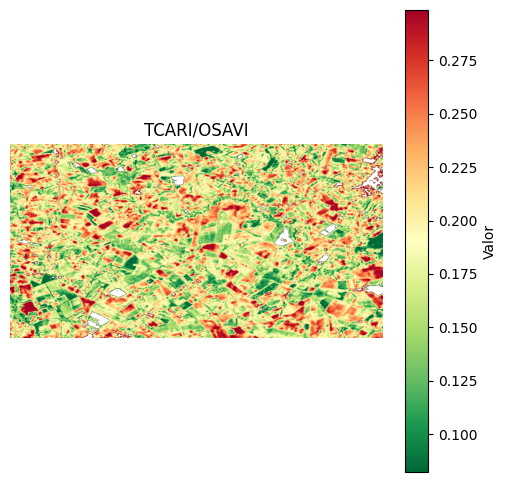

TCARI/OSAVI promedio = 0.1885
TCARI/OSAVI std = 0.0538

Interpretación:
Vigor máximo; vegetación muy densa y con alto contenido relativo de clorofila.


In [12]:
# 6. TCARI/OSAVI - ÍNDICE DE CLOROFILA AJUSTADO POR SUELO

print(" TCARI/OSAVI")

# DEFINICIÓN

definicion_tcari_osavi = ("El índice TCARI/OSAVI combina la sensibilidad del TCARI a las variaciones del contenido de clorofila con la capacidad del OSAVI para reducir"
                          "la influencia del suelo. Se utiliza para evaluar variaciones relacionadas con el estado de la vegetación y su contenido relativo de clorofila.")

print("\nDefinición:")
print(definicion_tcari_osavi)

# BANDAS Y CONDICIONES REQUERIDAS

bandas_requeridas = ["B03", "B04", "B05", "B08"]

faltantes = [ banda for banda in bandas_requeridas if banda not in bands ]

if not faltantes and "veg_mask" in globals():

    # CÁLCULO DEL TCARI

    red_valid = RED > 0

    TCARI = 3 * ((REDEDGE - RED) - 0.2 * (REDEDGE - GREEN) * (REDEDGE / (RED + epsilon)))

    # CÁLCULO DEL OSAVI
    OSAVI = (1.16 * (NIR - RED) / (NIR + RED + 0.16 + epsilon))


    # CÁLCULO DEL TCARI/OSAVI
    TCARI_OSAVI = TCARI / OSAVI

    # LIMPIEZA DEL ÍNDICE
    # Se conserva la escala nativa del índice.
    TCARI_OSAVI = np.where( np.isfinite(TCARI_OSAVI) & red_valid & veg_mask, TCARI_OSAVI, np.nan)

    # REGISTRO DEL RESULTADO
    indices_calculados["TCARI/OSAVI"] = {"bandas": bandas_requeridas, "escala": "Nativa", "rango_referencia": "0-1", "depende_de": "veg_mask"}

    print("\n✓ TCARI/OSAVI calculado correctamente.")
    print("  Escala nativa conservada.")
    print("  Rango de referencia utilizado: 0-1")

    # ESTADÍSTICAS

    valores_validos = TCARI_OSAVI[ np.isfinite(TCARI_OSAVI) ]

    if valores_validos.size > 0:

        promedio_tcari_osavi = np.nanmean(TCARI_OSAVI)
        desviacion_tcari_osavi = np.nanstd(TCARI_OSAVI)

        print("\nEstadísticas:")
        print( f"  Promedio = {promedio_tcari_osavi:.4f}")
        print( f"  Desviación estándar = "
               f"{desviacion_tcari_osavi:.4f}")
        print( f"  Mínimo = "
               f"{np.nanmin(TCARI_OSAVI):.4f}")
        print( f"  Máximo = "
               f"{np.nanmax(TCARI_OSAVI):.4f}")

    else:
        promedio_tcari_osavi = np.nan

        print("\n TCARI/OSAVI calculado, pero no hay "
              "valores válidos dentro de la máscara.")


    # MAPA DEL TCARI/OSAVI
    visualizar_indice(TCARI_OSAVI, "TCARI/OSAVI", cmap="RdYlGn_r")

    # INTERPRETACIÓN

    def interpretar_tcari_osavi(valor):

        if np.isnan(valor):
            return "Sin datos válidos para interpretar."

        elif valor < 0:
            return ("Valor inferior al rango de referencia; puede corresponder a un valor extremo o a condiciones no contempladas en la clasificación.")

        elif valor <= 0.2:
            return ("Vigor máximo; vegetación muy densa y con alto contenido relativo de clorofila.")

        elif valor <= 0.5:
            return ("Vegetación saludable; cultivo en condiciones normales y con desarrollo favorable.")

        elif valor <= 0.7:
            return ("Estrés leve o moderado; puede indicar el inicio de clorosis y requiere evaluar las condiciones nutricionales.")

        elif valor <= 1.0:
            return ("Estrés severo; puede estar asociado con clorosis avanzada, plagas, enfermedades o deficiencias nutricionales importantes.")

        else:
            return ("Sin vegetación útil o valor anómalo; puede corresponder a suelo expuesto, vegetación seca o posibles problemas de procesamiento.")

    print("\nInterpretación:")
    print(interpretar_tcari_osavi(promedio_tcari_osavi))


# CASOS EN LOS QUE NO SE PUEDE CALCULAR
elif faltantes:

    indices_no_calculados["TCARI/OSAVI"] = {"faltantes": faltantes}

    print("\n TCARI/OSAVI no calculado. "
          f"Faltan las bandas: {', '.join(faltantes)}"    )

elif "veg_mask" not in globals():

    indices_no_calculados["TCARI/OSAVI"] = {"faltantes": ["veg_mask"]}

    print("\n TCARI/OSAVI no calculado. "
          "No existe la máscara de vegetación generada por NDVI.")

 LAI-NDVI

Definición:
El LAI (Leaf Area Index) representa la cantidad de área foliar de la vegetación respecto al área de suelo que ocupa. En este casose estima a partir del NDVI mediante una relación empírica, permitiendo aproximar la densidad y estructura del dosel vegetal.

✓ LAI-NDVI calculado correctamente.
  Escala nativa conservada.
  Rango de referencia utilizado: 0-5

Estadísticas:
  Promedio = 1.2618
  Desviación estándar = 0.5230
  Mínimo = 0.0000
  Máximo = 2.6247


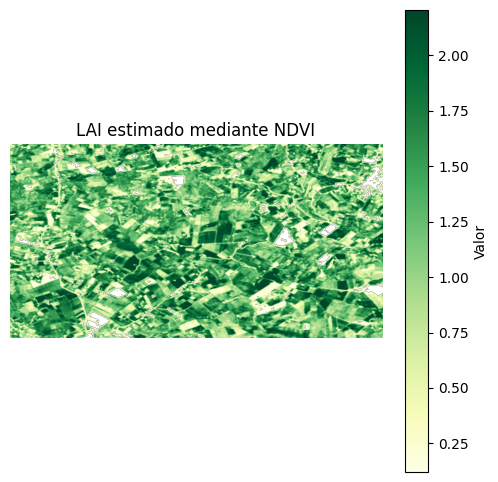

LAI estimado mediante NDVI promedio = 1.2618
LAI estimado mediante NDVI std = 0.5230

Interpretación:
Densidad vegetal media; corresponde a cultivos en desarrollo y vegetación moderada, generalmente adecuada para condiciones agrícolas.


In [13]:
# 7. LAI-NDVI - ÍNDICE DE ÁREA FOLIAR ESTIMADO MEDIANTE NDVI

print(" LAI-NDVI")

# DEFINICIÓN
definicion_lai = ("El LAI (Leaf Area Index) representa la cantidad de área foliar de la vegetación respecto al área de suelo que ocupa. En este caso"
                  "se estima a partir del NDVI mediante una relación empírica, permitiendo aproximar la densidad y estructura del dosel vegetal.")

print("\nDefinición:")
print(definicion_lai)

# CONDICIONES REQUERIDAS
if "NDVI" in globals() and "veg_mask" in globals():

    # CÁLCULO
    # Se limita el NDVI utilizado en la ecuación para evitar valores no válidos dentro del logaritmo.

    NDVI_safe = np.clip(NDVI, 0, 0.95)
    LAI_NDVI = -np.log((1 - NDVI_safe) / 0.69)
    LAI_NDVI = np.clip(LAI_NDVI, 0, None)      # único cambio de fondo: LAI no negativo

    # LIMPIEZA DEL ÍNDICE
    # LAI se conserva en su escala nativa.

    LAI_NDVI = np.where( np.isfinite(LAI_NDVI) & veg_mask, LAI_NDVI, np.nan)

    # REGISTRO DEL RESULTADO
    indices_calculados["LAI-NDVI"] = { "derivado_de": "NDVI", "escala": "Nativa", "rango_referencia": "0-5", "depende_de": "NDVI y veg_mask"}

    print("\n✓ LAI-NDVI calculado correctamente.")
    print("  Escala nativa conservada.")
    print("  Rango de referencia utilizado: 0-5")

    # ESTADÍSTICAS
    valores_validos = LAI_NDVI[np.isfinite(LAI_NDVI)]

    if valores_validos.size > 0:

        promedio_lai = np.nanmean(LAI_NDVI)
        desviacion_lai = np.nanstd(LAI_NDVI)

        print("\nEstadísticas:")
        print(f"  Promedio = {promedio_lai:.4f}")
        print(f"  Desviación estándar = {desviacion_lai:.4f}")
        print(f"  Mínimo = {np.nanmin(LAI_NDVI):.4f}")
        print(f"  Máximo = {np.nanmax(LAI_NDVI):.4f}")

    else:
        promedio_lai = np.nan
        print("\n LAI-NDVI calculado, pero no hay valores válidos dentro de la máscara.")

    # MAPA DEL LAI-NDVI
    visualizar_indice(LAI_NDVI, "LAI estimado mediante NDVI", cmap="YlGn")

    # INTERPRETACIÓN
    def interpretar_lai(valor):

        if np.isnan(valor):
            return "Sin datos válidos para interpretar."

        elif valor < 0:
            return "Valor fuera del rango de referencia."

        elif valor == 0:
            return ("Suelo desnudo o ausencia de vegetación.")

        elif valor < 1:
            return ("Baja densidad vegetal; puede corresponder a cultivos muy jóvenes o cobertura vegetal escasa.")

        elif valor < 3.5:
            return ("Densidad vegetal media; corresponde a cultivos en desarrollo y vegetación moderada, generalmente adecuada para condiciones agrícolas.")

        elif valor <= 5:
            return ("Alta densidad vegetal; indica una cobertura de dosel elevada y vegetación muy frondosa.")

        else:
            return ("Densidad vegetal muy alta o extrema; el valor supera el rango de referencia utilizado.")

    print("\nInterpretación:")
    print(interpretar_lai(promedio_lai))


# CASOS EN LOS QUE NO SE PUEDE CALCULAR
elif "NDVI" not in globals():

    indices_no_calculados["LAI-NDVI"] = {"faltantes": ["NDVI"]}

    print("\n LAI-NDVI no calculado. "
          "No existe el NDVI necesario para realizar la estimación."    )

elif "veg_mask" not in globals():

    indices_no_calculados["LAI-NDVI"] = {"faltantes": ["veg_mask"]}

    print("\n LAI-NDVI no calculado. "
          "No existe la máscara de vegetación generada por NDVI."    )

Firma Espectral

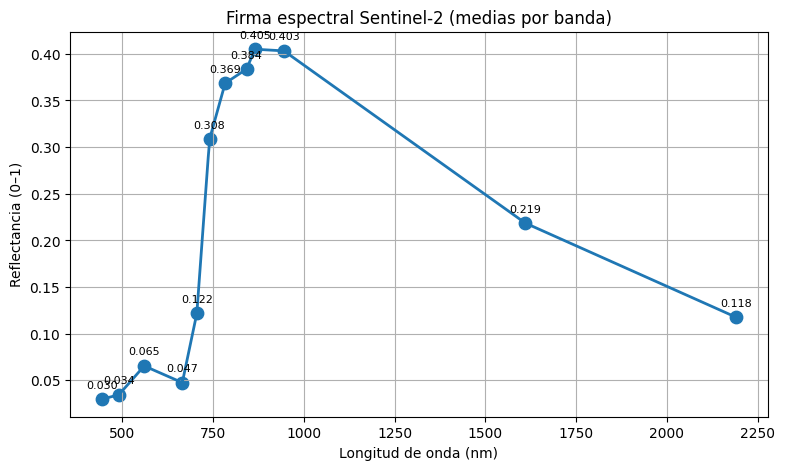

In [14]:
# Firma espectral ---
available_bands = sorted([(BAND_WAVELENGTHS[b], b) for b in bands.keys() if b in BAND_WAVELENGTHS])
wavelengths, medios = [], []
for wl, b in available_bands:
    wavelengths.append(wl)
    medios.append(np.nanmean(bands[b]))

wavelengths = np.array(wavelengths)
medios = np.array(medios)

# Interpolación para una curva suave (solo visual)
xx = np.linspace(wavelengths.min(), wavelengths.max(), 400)
yy = np.interp(xx, wavelengths, medios)

plt.figure(figsize=(9,5))
plt.plot(xx, yy, linewidth=2)
plt.scatter(wavelengths, medios, s=80)
for x,y in zip(wavelengths, medios):
    plt.annotate(f"{y:.3f}", (x,y), textcoords="offset points", xytext=(0,8), ha="center", fontsize=8)
plt.xlabel('Longitud de onda (nm)')
plt.ylabel('Reflectancia (0–1)')
plt.title('Firma espectral Sentinel-2 (medias por banda)')
plt.grid(True)
plt.show()

Proceso de Normalizacion de Indices

In [15]:
# RCI: rango de referencia [0, 15]
RCI_n = 2 * ((RCI - 0) / (15 - 0)) - 1
RCI_n = np.clip(RCI_n, -1, 1)

# TCARI/OSAVI: rango de referencia [0, 1]
TCARI_OSAVI_n = 2 * ((1 - TCARI_OSAVI) / (1 - 0)) - 1
TCARI_OSAVI_n = np.clip(TCARI_OSAVI_n, -1, 1)

# LAI-NDVI: rango de referencia [0, 5]
LAI_NDVI_n = 2 * ((LAI_NDVI - 0) / (5 - 0)) - 1
LAI_NDVI_n = np.clip(LAI_NDVI_n, -1, 1)

# Aplicar máscara de vegetación
RCI_n[~veg_mask] = np.nan
TCARI_OSAVI_n[~veg_mask] = np.nan
LAI_NDVI_n[~veg_mask] = np.nan

# ESTADÍSTICAS
print("RCI normalizado:")
print("Promedio =", np.nanmean(RCI_n))

print("\nTCARI/OSAVI normalizado:")
print("Promedio =", np.nanmean(TCARI_OSAVI_n))

print("\nLAI-NDVI normalizado:")
print("Promedio =", np.nanmean(LAI_NDVI_n))

def normalizar_percentil(indice, veg_mask, p_bajo=2, p_alto=98):
    valores_validos = indice[veg_mask & np.isfinite(indice)]
    minimo = np.percentile(valores_validos, p_bajo)
    maximo = np.percentile(valores_validos, p_alto)
    normalizado = 2 * ((indice - minimo) / (maximo - minimo)) - 1
    return np.clip(normalizado, -1, 1)

RCI_n = normalizar_percentil(RCI, veg_mask)
LAI_NDVI_n = normalizar_percentil(LAI_NDVI, veg_mask)

RCI normalizado:
Promedio = -0.7001723

TCARI/OSAVI normalizado:
Promedio = 0.6227533

LAI-NDVI normalizado:
Promedio = -0.49526715


Estimacion de Clorofila


✓ Clorofila calculada.


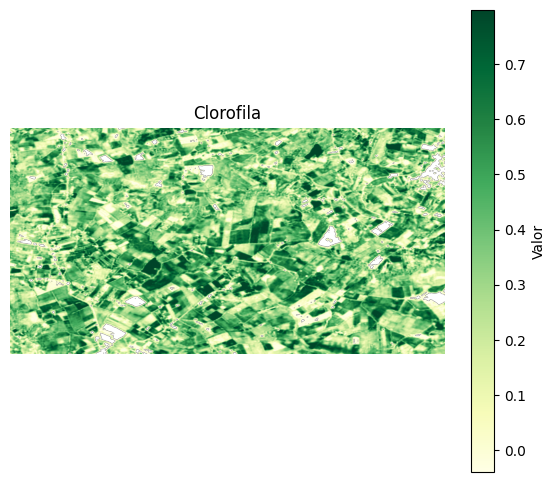

Clorofila:
  Promedio = 0.3612
  Desviación estándar = 0.2113
  Mínimo = -0.7182
  Máximo = 0.9205

✓ Nitrógeno calculado.


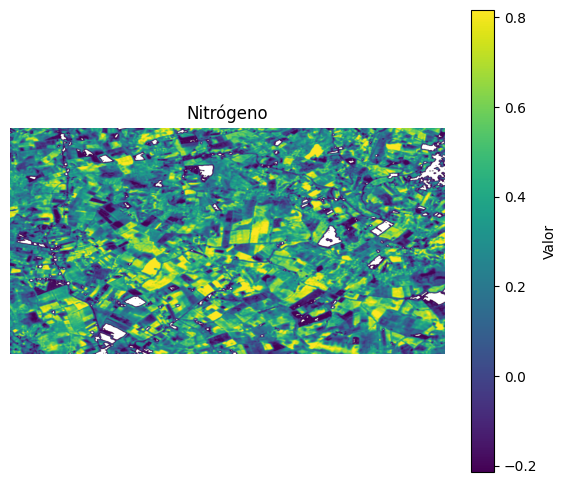

Nitrógeno:
  Promedio = 0.2899
  Desviación estándar = 0.2629
  Mínimo = -0.7534
  Máximo = 0.8958

✓ Estado hídrico calculado.


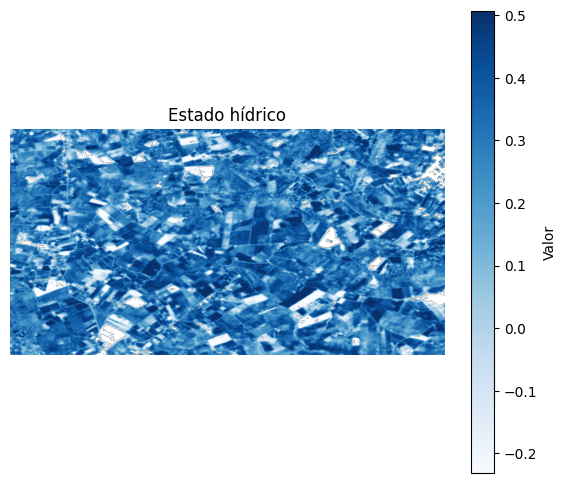

Estado hídrico:
  Promedio = 0.2684
  Desviación estándar = 0.1695
  Mínimo = -0.5439
  Máximo = 0.6778

✓ Densidad del dosel calculada.


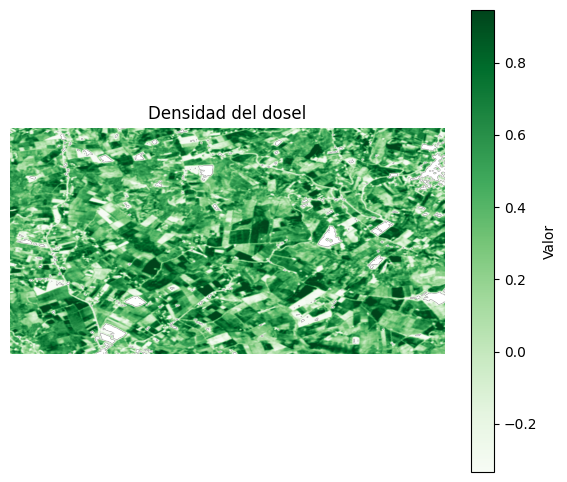

Densidad del dosel:
  Promedio = 0.3995
  Desviación estándar = 0.3144
  Mínimo = -0.6024
  Máximo = 0.9846

✓ Vigor vegetativo calculado.


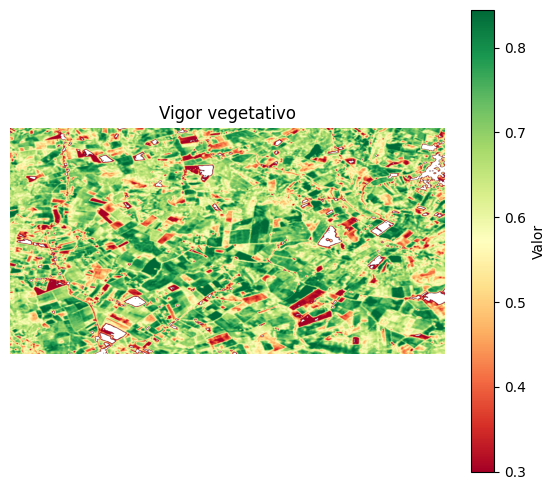

Vigor vegetativo:
  Promedio = 0.6474
  Desviación estándar = 0.1300
  Mínimo = -0.2938
  Máximo = 0.9136
 RESUMEN DE PARÁMETROS
Calculados: 5
  ✓ Clorofila
  ✓ Nitrógeno
  ✓ Estado hídrico
  ✓ Densidad del dosel
  ✓ Vigor vegetativo


In [16]:
# CÁLCULO PARÁMETROS
parametros_calculados = []
parametros_no_calculados = {}

# FUNCIÓN DE VALIDACIÓN DE COMPONENTES

def validar_componentes(nombre, requeridos):
    """Comprueba que todos los componentes necesarios estén disponibles antes de calcular un parámetro."""

    faltantes = [componente for componente in requeridos if componente not in globals()]

    if faltantes:
        parametros_no_calculados[nombre] = {"faltantes": faltantes}

        print(f" {nombre} no calculado.")
        print(f"  Faltan: {', '.join(faltantes)}")

        return False

    if "veg_mask" not in globals():

        parametros_no_calculados[nombre] = {"faltantes": ["veg_mask"]}

        print(f" {nombre} no calculado.")
        print("   Falta: veg_mask")

        return False
    return True


# FUNCIÓN DE DEPURACIÓN
def depurar_parametro(parametro, mascara):
    """Elimina valores no finitos y aplica la máscara de vegetación."""

    parametro = np.asarray(parametro, dtype=np.float32)

    if parametro.shape != mascara.shape:

        raise ValueError("El parámetro y la máscara de vegetación tienen dimensiones diferentes.")

    parametro = np.where(np.isfinite(parametro), parametro, np.nan)
    parametro = np.where(mascara, parametro, np.nan)

    return parametro

# FUNCIÓN DE VISUALIZACIÓN Y ESTADÍSTICAS
def visualizar_parametro(parametro, titulo, cmap="viridis"):

    valores = parametro[np.isfinite(parametro)]

    if valores.size == 0:
        print(f" {titulo}: no hay valores válidos.")

        return

    vmin = np.percentile(valores, 2)
    vmax = np.percentile(valores,98)

    # Evita problemas si todos los valores son iguales
    if vmin == vmax:

        vmin = np.min(valores)
        vmax = np.max(valores)

    plt.figure(figsize=(7, 6))
    plt.imshow(parametro, cmap=cmap, vmin=vmin, vmax=vmax)
    plt.title(titulo)
    plt.colorbar( label="Valor" )
    plt.axis("off")
    plt.show()

    print( f"{titulo}:")

    print( f"  Promedio = "
           f"{np.nanmean(parametro):.4f}")

    print( f"  Desviación estándar = "
           f"{np.nanstd(parametro):.4f}")

    print( f"  Mínimo = "
           f"{np.nanmin(parametro):.4f}")

    print( f"  Máximo = "f"{np.nanmax(parametro):.4f}")

# 1. CLOROFILA

requeridos = ["NDRE", "RCI_n", "TCARI_OSAVI_n", "EVI"]

if validar_componentes("Clorofila", requeridos):

    Clorofila = (0.40 * NDRE + 0.30 * RCI_n + 0.20 * TCARI_OSAVI_n + 0.10 * EVI)

    Clorofila = depurar_parametro(Clorofila, veg_mask)

    parametros_calculados.append("Clorofila")

    print("\n✓ Clorofila calculada.")

    visualizar_parametro(Clorofila, "Clorofila", cmap="YlGn")

# 2. NITRÓGENO

requeridos = ["NDRE", "RCI_n", "TCARI_OSAVI_n", "LAI_NDVI_n"]

if validar_componentes("Nitrógeno", requeridos):

    Nitrogeno = ( 0.35 * NDRE + 0.30 * RCI_n + 0.20 * TCARI_OSAVI_n + 0.15 * LAI_NDVI_n )

    Nitrogeno = depurar_parametro(Nitrogeno, veg_mask)

    parametros_calculados.append("Nitrógeno")

    print("\n✓ Nitrógeno calculado.")

    visualizar_parametro(Nitrogeno, "Nitrógeno", cmap="viridis")

# 3. ESTADO HÍDRICO

requeridos = ["NDMI"]

if validar_componentes("Estado hídrico", requeridos):

    Estado_hidrico = depurar_parametro(NDMI, veg_mask)

    parametros_calculados.append("Estado hídrico")

    print("\n✓ Estado hídrico calculado.")

    visualizar_parametro(Estado_hidrico, "Estado hídrico", cmap="Blues")

# 4. DENSIDAD DEL DOSEL

requeridos = ["LAI_NDVI_n", "NDVI", "EVI"]

if validar_componentes("Densidad del dosel", requeridos):

    Densidad_dosel = (0.50 * LAI_NDVI_n + 0.30 * NDVI + 0.20 * EVI)

    Densidad_dosel = depurar_parametro( Densidad_dosel, veg_mask)

    parametros_calculados.append("Densidad del dosel")

    print("\n✓ Densidad del dosel calculada.")

    visualizar_parametro(Densidad_dosel, "Densidad del dosel", cmap="Greens")

# 5. VIGOR VEGETATIVO

requeridos = ["NDVI", "EVI", "NDRE"]

if validar_componentes("Vigor vegetativo", requeridos):

    Vigor_vegetativo = ( 0.40 * NDVI + 0.35 * EVI + 0.25 * NDRE)

    Vigor_vegetativo = depurar_parametro( Vigor_vegetativo, veg_mask)

    parametros_calculados.append( "Vigor vegetativo")

    print("\n✓ Vigor vegetativo calculado.")

    visualizar_parametro(Vigor_vegetativo, "Vigor vegetativo", cmap="RdYlGn")

# RESUMEN

print(" RESUMEN DE PARÁMETROS")

print(f"Calculados: "
      f"{len(parametros_calculados)}")

for parametro in parametros_calculados:

    print(f"  ✓ {parametro}")

if parametros_no_calculados:

    print(f"\nNo calculados: "
          f"{len(parametros_no_calculados)}")

    for parametro, informacion in parametros_no_calculados.items():

        faltantes = informacion["faltantes"]

        print(f"  ⚠ {parametro} → "
            f"faltan: {', '.join(faltantes)}")


NDRE - Clorofila: correlación positiva muy fuerte (r = 0.98)


/tmp/ipykernel_1033/4209025165.py:58: RankWarning: Polyfit may be poorly conditioned
  pendiente, intercepto = np.polyfit(x, y, 1)


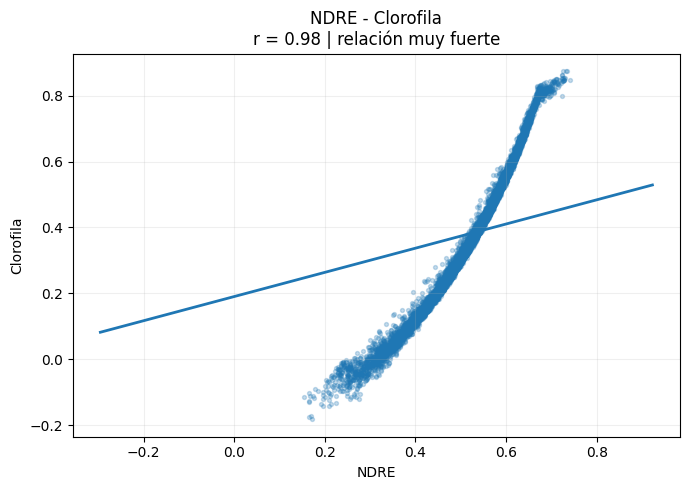


NDVI - Densidad del dosel: correlación positiva muy fuerte (r = 0.96)


/tmp/ipykernel_1033/4209025165.py:58: RankWarning: Polyfit may be poorly conditioned
  pendiente, intercepto = np.polyfit(x, y, 1)


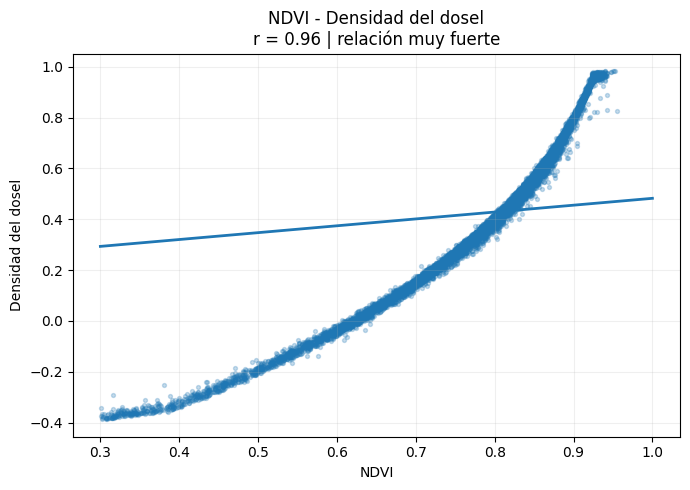


NDVI - Vigor vegetativo: correlación positiva muy fuerte (r = 0.96)


/tmp/ipykernel_1033/4209025165.py:58: RankWarning: Polyfit may be poorly conditioned
  pendiente, intercepto = np.polyfit(x, y, 1)


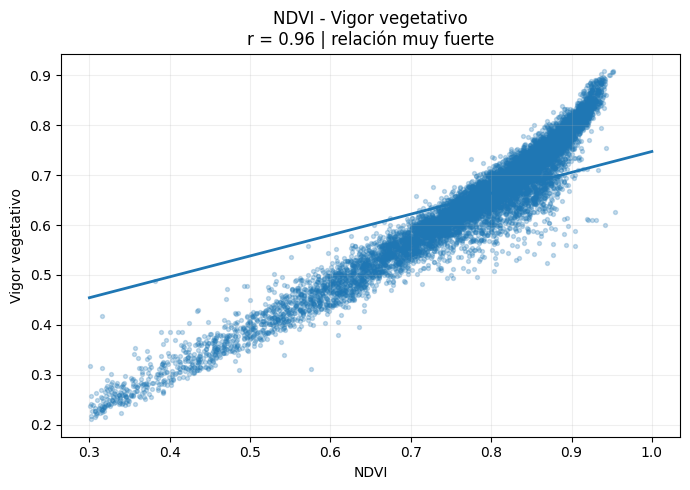


 MAYOR CORRELACIÓN ASOCIADA CON NDVI

✓ NDVI - Densidad del dosel: r = 0.96
 RESUMEN DEL ANÁLISIS


,indice,parametro,r,p,n,fuerza,direccion
0,NDRE,Clorofila,0.977454,0.0,2968736,muy fuerte,positiva
1,NDVI,Densidad del dosel,0.963558,0.0,2968742,muy fuerte,positiva
2,NDVI,Vigor vegetativo,0.963527,0.0,2968742,muy fuerte,positiva


In [17]:
# FUNCIÓN PARA CALCULAR Y MOSTRAR CORRELACIÓN

def analizar_correlacion(indice, parametro, nombre_indice, nombre_parametro):

    mascara = ( np.isfinite(indice) & np.isfinite(parametro))

    x = indice[mascara]
    y = parametro[mascara]

    if x.size < 3:
        print(f" No hay suficientes datos para analizar "
              f"{nombre_indice} - {nombre_parametro}.")
        return None

    # Correlación de Pearson
    r, p = pearsonr(x, y)

    # Interpretación de la fuerza
    if abs(r) < 0.30:
        fuerza = "baja"
    elif abs(r) < 0.60:
        fuerza = "moderada"
    elif abs(r) < 0.80:
        fuerza = "fuerte"
    else:
        fuerza = "muy fuerte"
    if r > 0:
        direccion = "positiva"
    elif r < 0:
        direccion = "negativa"
    else:
        direccion = "sin relación lineal"

    # Texto puntual para el usuario

    print(f"\n{nombre_indice} - {nombre_parametro}: "
          f"correlación {direccion} {fuerza} (r = {r:.2f})")

    # Gráfico de dispersión
    # Para visualización se utiliza una muestra si hay demasiados píxeles.
    max_puntos = 10000

    if x.size > max_puntos:

        rng = np.random.default_rng(42)

        indices_muestra = rng.choice(x.size, size=max_puntos, replace=False)

        x_grafico = x[indices_muestra]
        y_grafico = y[indices_muestra]

    else:

        x_grafico = x
        y_grafico = y

    # Línea de tendencia
    pendiente, intercepto = np.polyfit(x, y, 1)

    x_linea = np.linspace(np.min(x), np.max(x), 100)
    y_linea = (pendiente * x_linea + intercepto)

    plt.figure(figsize=(7, 5))

    plt.scatter(x_grafico, y_grafico, alpha=0.25, s=8)

    plt.plot(x_linea, y_linea, linewidth=2 )

    plt.xlabel(nombre_indice)
    plt.ylabel(nombre_parametro)

    plt.title(f"{nombre_indice} - {nombre_parametro}\n"
              f"r = {r:.2f} | relación {fuerza}" )

    plt.grid(alpha=0.2)

    plt.tight_layout()
    plt.show()

    return {"indice": nombre_indice, "parametro": nombre_parametro, "r": r, "p": p, "n": x.size, "fuerza": fuerza, "direccion": direccion }

# RESULTADOS
resultados_correlacion = []

# 1. NDRE - CLOROFILA
if "NDRE" in globals() and "Clorofila" in globals():

    resultado = analizar_correlacion(NDRE, Clorofila, "NDRE", "Clorofila" )

    if resultado is not None:
        resultados_correlacion.append(resultado)

else:
    print("\n No se puede analizar NDRE - Clorofila." )

# 2. NDVI - DENSIDAD DEL DOSEL
if "NDVI" in globals() and "Densidad_dosel" in globals():

    resultado = analizar_correlacion(NDVI, Densidad_dosel, "NDVI", "Densidad del dosel" )

    if resultado is not None:
        resultados_correlacion.append(resultado)

else:

    print("\n No se puede analizar NDVI - Densidad del dosel." )

# 3. NDVI - VIGOR VEGETATIVO

if "NDVI" in globals() and "Vigor_vegetativo" in globals():

    resultado = analizar_correlacion(NDVI, Vigor_vegetativo, "NDVI", "Vigor vegetativo" )

    if resultado is not None:
        resultados_correlacion.append(resultado)

else:
    print("\n No se puede analizar NDVI - Vigor vegetativo." )

# 4. SELECCIÓN DE LA MAYOR RELACIÓN CON NDVI

resultados_ndvi = [resultado for resultado in resultados_correlacion if resultado["indice"] == "NDVI" ]

if resultados_ndvi:

    mejor_resultado = max(resultados_ndvi,
        key=lambda resultado: abs(resultado["r"]))

    print( "\n" + "=" * 60)

    print( " MAYOR CORRELACIÓN ASOCIADA CON NDVI")

    print( f"\n✓ NDVI - "
        f"{mejor_resultado['parametro']}: "
        f"r = {mejor_resultado['r']:.2f}" )


# 5. RESUMEN

if resultados_correlacion:
    tabla_correlacion = pd.DataFrame(resultados_correlacion )

    print( " RESUMEN DEL ANÁLISIS")

    display(tabla_correlacion[["indice", "parametro", "r", "p", "n", "fuerza", "direccion"]])

In [18]:
nombres_resultados = [
    "NDVI",
    "NDRE",
    "EVI",
    "NDMI",
    "RCI",
    "RCI_n",
    "TCARI_OSAVI",
    "TCARI_OSAVI_n",
    "LAI_NDVI",
    "LAI_NDVI_n",
    "Clorofila",
    "Nitrogeno",
    "Estado_hidrico",
    "Densidad_dosel",
    "Vigor_vegetativo"
]

resumen = []

for nombre in nombres_resultados:

    if nombre not in globals():
        continue

    array = np.asarray(globals()[nombre])

    valores = array[np.isfinite(array)]

    if valores.size == 0:
        continue

    resumen.append({
        "Resultado": nombre,
        "Media": np.mean(valores),
        "Mínimo": np.min(valores),
        "Máximo": np.max(valores),
        "Desv. estándar": np.std(valores),
        "Píxeles válidos": valores.size
    })

tabla_resultados = pd.DataFrame(resumen)

print("\n" + "=" * 75)
print(" VALORES GENERADOS POR EL APLICATIVO")
print("=" * 75)

display(
    tabla_resultados.style.format({
        "Media": "{:.4f}",
        "Mínimo": "{:.4f}",
        "Máximo": "{:.4f}",
        "Desv. estándar": "{:.4f}"
    })
)


 VALORES GENERADOS POR EL APLICATIVO


,Resultado,Media,Mínimo,Máximo,Desv. estándar,Píxeles válidos
0,NDVI,0.7751,0.3000,1.0000,0.1282,2968742
1,NDRE,0.5102,-0.2954,0.9229,0.0997,2968742
2,EVI,0.5994,-1.0000,1.0000,0.1675,2968742
3,NDMI,0.2684,-0.5439,0.6778,0.1695,2968742
4,RCI,2.2487,-0.4561,23.9235,0.8409,2968742
5,RCI_n,-0.0911,-1.0000,1.0000,0.4870,2968742
6,TCARI_OSAVI,0.1885,-3.7834,2.6335,0.0538,2968736
7,TCARI_OSAVI_n,0.6228,-1.0000,1.0000,0.1062,2968736
8,LAI_NDVI,1.2618,0.0000,2.6247,0.5230,2968742
9,LAI_NDVI_n,0.0942,-1.0000,1.0000,0.4948,2968742


In [19]:
# GUARDADO DE MAPAS Y RESULTADOS

# Carpetas
MAPAS_DIR = os.path.join(OUTDIR, "mapas_geotiff")
PNG_DIR = os.path.join(OUTDIR, "mapas_png")
os.makedirs(MAPAS_DIR, exist_ok=True)
os.makedirs(PNG_DIR, exist_ok=True)

# Resultados disponibles
nombres = ["NDVI", "NDRE", "EVI", "NDMI", "RCI", "RCI_n", "TCARI_OSAVI", "TCARI_OSAVI_n", "LAI_NDVI", "LAI_NDVI_n", "Clorofila", "Nitrogeno", "Estado_hidrico","Densidad_dosel", "Vigor_vegetativo"]

resultados = {nombre: globals()[nombre] for nombre in nombres if nombre in globals()}

# Referencia espacial: B04
referencias = [f for f in os.listdir(BAND_FOLDER) if f.lower().endswith((".tif", ".tiff")) and "_B04_" in f.upper()]

if len(referencias) != 1:
    raise ValueError("Se requiere exactamente un archivo B04 como referencia.")

with rasterio.open(os.path.join(BAND_FOLDER, referencias[0])) as src:
    shape_ref = src.shape
    crs_ref = src.crs
    transform_ref = src.transform

# Función para guardar GeoTIFF
def guardar_geotiff(array, nombre):
    if array.shape != shape_ref:
        print(f"{nombre}: dimensiones incompatibles. No se guarda.")
        return False

    datos = np.where(np.isfinite(array), array, -9999).astype(np.float32)

    ruta = os.path.join(MAPAS_DIR, f"{nombre}.tif")

    perfil = {"driver": "GTiff",           "height": datos.shape[0],    "width": datos.shape[1],
              "count": 1,                  "dtype": "float32",          "crs": crs_ref,
              "transform": transform_ref,  "nodata": -9999,             "compress": "lzw",
              "predictor": 3 }

    with rasterio.open(ruta, "w", **perfil) as dst:
        dst.write(datos, 1)

    return ruta

# Guardar resultados
estadisticas = []

for nombre, array in resultados.items():

    valores = array[np.isfinite(array)]

    if valores.size == 0:
        print(f"{nombre}: sin valores válidos.")
        continue

    # GeoTIFF
    guardar_geotiff(array, nombre)

    # Estadísticas
    estadisticas.append([ nombre, np.nanmean(array), np.nanstd(array), np.nanmin(array), np.nanmax(array), valores.size])

    # PNG
    vmin, vmax = np.percentile(valores, [2, 98])

    plt.figure(figsize=(6, 5))
    plt.imshow(array, cmap="RdYlGn", vmin=vmin, vmax=vmax)
    plt.colorbar(label=nombre)
    plt.title(nombre)
    plt.axis("off")
    plt.tight_layout()

    plt.savefig(os.path.join(PNG_DIR, f"{nombre}.png"), dpi=300, bbox_inches="tight")
    plt.close()

# CSV
csv_path = os.path.join(OUTDIR, "resultados_stats.csv")

with open(csv_path, "w", newline="", encoding="utf-8") as archivo:
    writer = csv.writer(archivo)

    writer.writerow(["resultado", "media", "desviacion_estandar", "minimo", "maximo", "pixeles_validos"])

    writer.writerows(estadisticas)

print(" GUARDADO COMPLETADO")
print(f"GeoTIFF → {MAPAS_DIR}")
print(f"PNG     → {PNG_DIR}")
print(f"CSV     → {csv_path}")
print(f"Resultados guardados: {len(estadisticas)}")

 GUARDADO COMPLETADO
GeoTIFF → /content/spectral_results/mapas_geotiff
PNG     → /content/spectral_results/mapas_png
CSV     → /content/spectral_results/resultados_stats.csv
Resultados guardados: 15
